# Math 550 HW 9 Elisa Bucci

In [1]:
import warnings
warnings.filterwarnings('ignore', message='ModelSpec will move')

import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from sklearn.model_selection import KFold, cross_validate
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize,
                         poly,
                         bs,
                         sklearn_sm)

## Exercise 2

The idea in every case: when λ = ∞, any g with a nonzero penalty gives an infinite objective. So ĝ must make the integral of [g^(m)(x)]² equal to zero, which means g^(m) ≡ 0. Among all such functions, ĝ is the one that minimizes the RSS. When λ = 0 only the RSS matters.

a) λ = ∞, m = 0. The penalty is the integral of g(x)², so it vanishes only if g ≡ 0. Then ĝ(x) = 0, the horizontal line at height zero, whatever the data are.

b) λ = ∞, m = 1. The penalty forces g' ≡ 0, so g is a constant c. Minimizing Σ(yi − c)² gives c = ȳ, so ĝ is the horizontal line at the sample mean of the y values.

c) λ = ∞, m = 2. The penalty forces g'' ≡ 0, so g is linear, g(x) = β0 + β1x. Minimizing the RSS over lines gives the ordinary least squares regression line.

d) λ = ∞, m = 3. The penalty forces g''' ≡ 0, so g is quadratic, g(x) = β0 + β1x + β2x². ĝ is the least squares quadratic, which is polynomial regression of degree 2.

e) λ = 0, m = 3. There is no penalty, so ĝ just minimizes the RSS. Any function passing through all n points makes the RSS zero, so ĝ interpolates the data (m plays no role). The fit has zero training error and very high variance. In the sketch, one such interpolant is the degree n − 1 polynomial through the n points; its large swings between points show how badly it overfits.

The sketches below are drawn on simulated data. Fits b), c) and d) use sm.OLS on an intercept-only design and on poly() designs of degree 1 and 2.

In [2]:
rng = np.random.default_rng(1)
n = 10
x = np.sort(rng.uniform(-2, 2, n))
y = 1 + x - 0.5 * x**2 + rng.normal(scale=0.7, size=n)
df = pd.DataFrame({'x': x, 'y': y})

x_grid = np.linspace(-2, 2, 400)
grid = pd.DataFrame({'x': x_grid})

def fit_poly(degree):
    """Least squares polynomial fit of a given degree, evaluated on the grid."""
    if degree == 0:
        X = np.ones((n, 1))
        X_new = np.ones((x_grid.shape[0], 1))
    else:
        design = MS([poly('x', degree=degree)], intercept=True)
        X = design.fit_transform(df)
        X_new = design.transform(grid)
    results = sm.OLS(df['y'], X).fit()
    return results.predict(X_new)

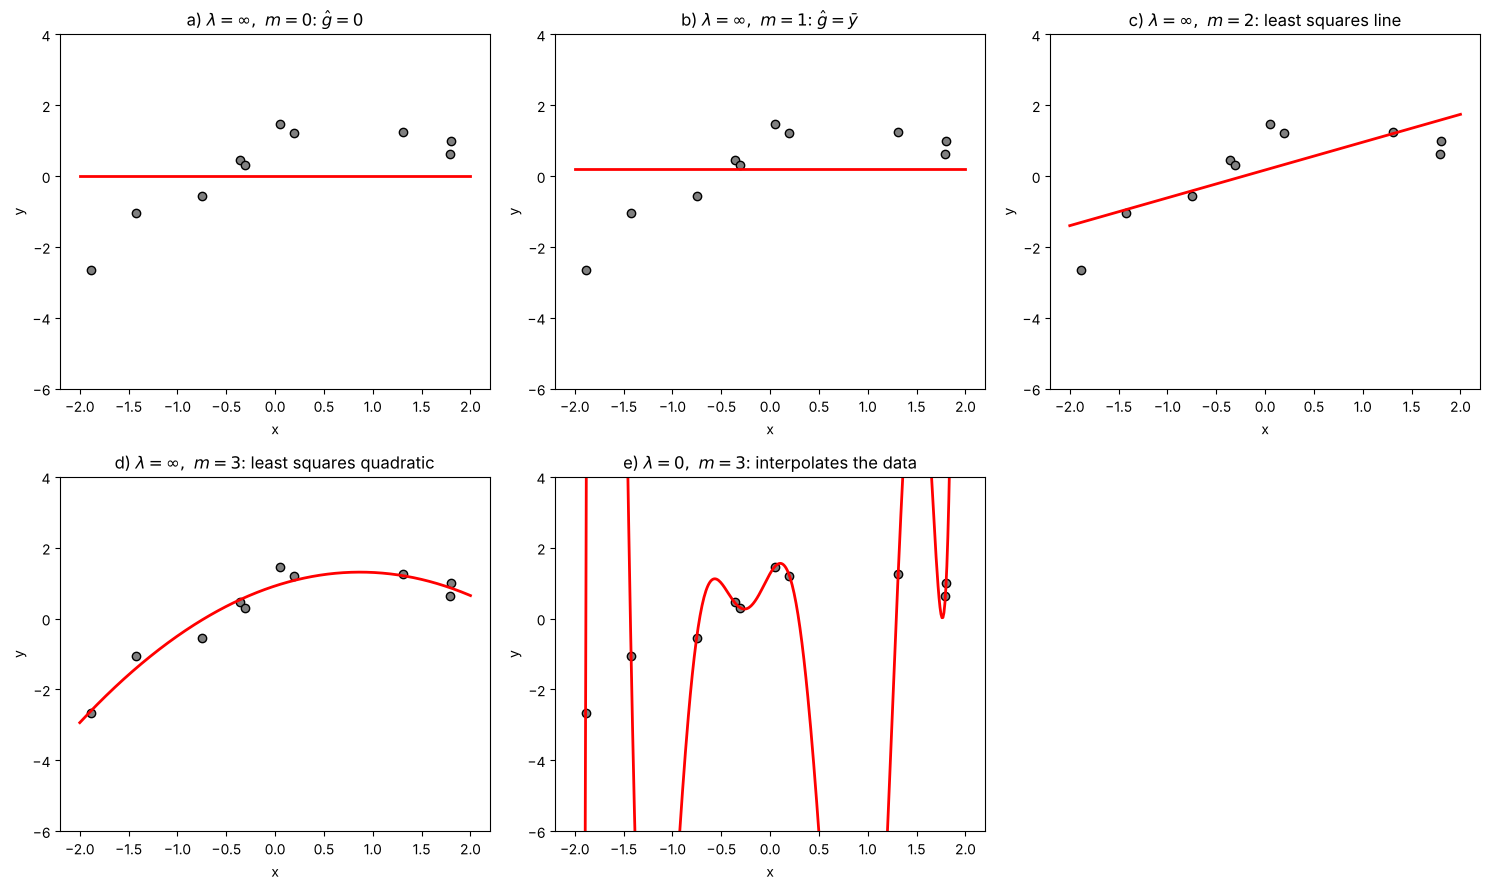

In [3]:
g_a = np.zeros_like(x_grid)   # a) g = 0
g_b = fit_poly(0)             # b) constant = mean(y)
g_c = fit_poly(1)             # c) least squares line
g_d = fit_poly(2)             # d) least squares quadratic
g_e = fit_poly(n - 1)         # e) interpolates all n points

fits = [(g_a, r'a) $\lambda=\infty,\ m=0$: $\hat g = 0$'),
        (g_b, r'b) $\lambda=\infty,\ m=1$: $\hat g = \bar y$'),
        (g_c, r'c) $\lambda=\infty,\ m=2$: least squares line'),
        (g_d, r'd) $\lambda=\infty,\ m=3$: least squares quadratic'),
        (g_e, r'e) $\lambda=0,\ m=3$: interpolates the data')]

fig, axes = subplots(2, 3, figsize=(15, 9))
for ax, (g, title) in zip(axes.flatten(), fits):
    ax.scatter(df['x'], df['y'], facecolor='gray', edgecolor='k')
    ax.plot(x_grid, g, 'r', linewidth=2)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_ylim(-6, 4)
axes.flatten()[-1].axis('off')
fig.tight_layout()

## Exercise 5

a) As λ → ∞, the penalty forces ĝ1''' ≡ 0 and ĝ2'''' ≡ 0. So ĝ1 becomes the least squares quadratic and ĝ2 the least squares cubic. Every quadratic is also a cubic (with zero cubic coefficient), so the cubic is fit over a larger class of functions and its training RSS can only be smaller or equal. ĝ2 will have the smaller (or equal) training RSS.

b) It depends on the true relationship f. If f is close to quadratic or simpler, the extra cubic term in ĝ2 mostly fits noise: it adds variance without reducing bias, so ĝ1 should have the smaller test RSS. If f has substantial cubic-type curvature, the quadratic ĝ1 is biased and ĝ2 should do better. This is the bias-variance trade-off, and neither curve is guaranteed to win.

c) With λ = 0 the penalty disappears, so both problems reduce to minimizing the RSS alone. Both ĝ1 and ĝ2 interpolate the training points, so both have training RSS equal to zero. Their test RSS is the same in the sense that both are unpenalized interpolants with the same severe overfitting: since m no longer enters the objective, there is no reason to expect either one to do better on test data.

## Exercise 9

Cross-validation throughout uses 10-fold CV with KFold(10, shuffle=True, random_state=0) and the sklearn_sm wrapper, as in the Chapter 5 lab.

In [4]:
Boston = load_data('Boston')
y = Boston['nox']
dis_grid = np.linspace(Boston['dis'].min(), Boston['dis'].max(), 200)
df_new = pd.DataFrame({'dis': dis_grid})
cv = KFold(n_splits=10, shuffle=True, random_state=0)

a) Cubic polynomial regression of nox on dis.

                          coef  std err        t  P>|t|
intercept               0.5547    0.003  201.021    0.0
poly(dis, degree=3)[0] -2.0031    0.062  -32.271    0.0
poly(dis, degree=3)[1]  0.8563    0.062   13.796    0.0
poly(dis, degree=3)[2] -0.3180    0.062   -5.124    0.0
RSS: 1.9341


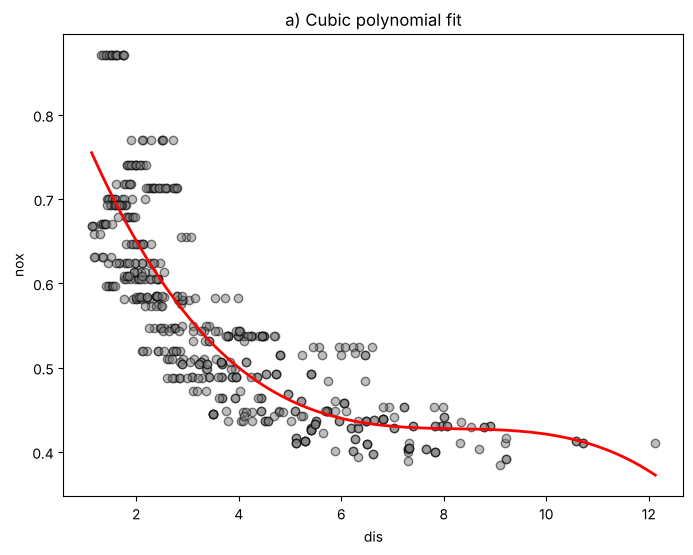

In [5]:
design = MS([poly('dis', degree=3)], intercept=True)
X = design.fit_transform(Boston)
M_cubic = sm.OLS(y, X).fit()
print(summarize(M_cubic))
print('RSS:', round(np.sum(M_cubic.resid**2), 4))

fig, ax = subplots(figsize=(8, 6))
ax.scatter(Boston['dis'], y, facecolor='gray', edgecolor='k', alpha=0.5)
ax.plot(dis_grid, M_cubic.predict(design.transform(df_new)), 'r', linewidth=2)
ax.set_xlabel('dis'); ax.set_ylabel('nox')
ax.set_title('a) Cubic polynomial fit');

All three orthogonal polynomial terms are highly significant (p < 0.001) and the RSS is 1.934. The fitted curve shows nox dropping steeply as dis goes from about 1 to 6 and then leveling off near 0.4: pollution is highest close to the employment centers.

b) Polynomial fits of degree 1 to 10 and their RSS.

,degree,RSS
0,1,2.7686
1,2,2.0353
2,3,1.9341
3,4,1.9330
4,5,1.9153
5,6,1.8783
6,7,1.8495
7,8,1.8356
8,9,1.8333
9,10,1.8322


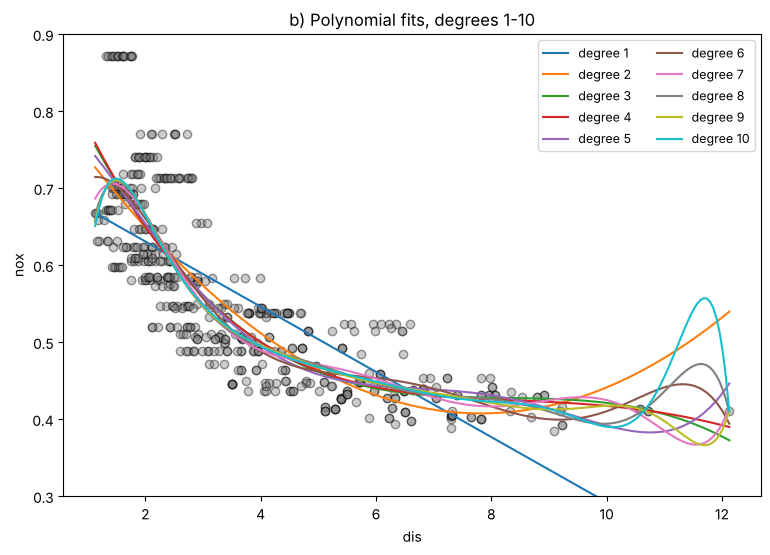

In [6]:
fig, ax = subplots(figsize=(9, 6))
ax.scatter(Boston['dis'], y, facecolor='gray', edgecolor='k', alpha=0.4)
rss_poly = []
for d in range(1, 11):
    design = MS([poly('dis', degree=d)], intercept=True)
    M = sm.OLS(y, design.fit_transform(Boston)).fit()
    rss_poly.append(np.sum(M.resid**2))
    ax.plot(dis_grid, M.predict(design.transform(df_new)), linewidth=1.5,
            label=f'degree {d}')
ax.set_ylim(0.3, 0.9)
ax.set_xlabel('dis'); ax.set_ylabel('nox')
ax.set_title('b) Polynomial fits, degrees 1-10')
ax.legend(ncol=2, fontsize=9)
pd.DataFrame({'degree': range(1, 11), 'RSS': np.round(rss_poly, 4)})

The training RSS decreases with every added degree, because the models are nested: from 2.769 (degree 1) to 1.832 (degree 10). After degree 3 the gains are tiny. The high-degree fits wiggle badly at the right end (dis > 10), where data are sparse.

c) Choosing the degree by 10-fold cross-validation.

best degree: 3


,degree,CV MSE
0,1,0.005520
1,2,0.004060
2,3,0.003854
3,4,0.003869
4,5,0.004087
5,6,0.005254
6,7,0.008772
7,8,0.005806
8,9,0.016402
9,10,0.008476


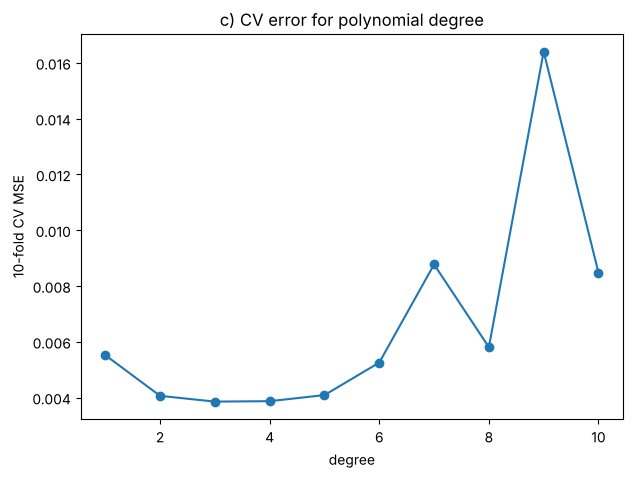

In [7]:
cv_poly = []
for d in range(1, 11):
    M = sklearn_sm(sm.OLS, MS([poly('dis', degree=d)], intercept=True))
    res = cross_validate(M, Boston[['dis']], y, cv=cv)
    cv_poly.append(np.mean(res['test_score']))
print('best degree:', int(np.argmin(cv_poly)) + 1)

fig, ax = subplots(figsize=(7, 5))
ax.plot(range(1, 11), cv_poly, 'o-')
ax.set_xlabel('degree'); ax.set_ylabel('10-fold CV MSE')
ax.set_title('c) CV error for polynomial degree')
pd.DataFrame({'degree': range(1, 11), 'CV MSE': np.round(cv_poly, 6)})

The CV error is smallest at degree 3 (MSE about 0.00385), with degree 4 essentially tied. Beyond that the CV error grows and becomes unstable, because high-degree fits have huge variance in the sparse right tail. A cubic is the right choice, consistent with b): the improvement from degree 2 to 3 is real, while later RSS decreases only fit noise.

d) Regression spline with bs() and four degrees of freedom.

              coef  std err       t  P>|t|
intercept   0.7345    0.015  50.306  0.000
bs(dis)[0] -0.0581    0.022  -2.658  0.008
bs(dis)[1] -0.4636    0.024 -19.596  0.000
bs(dis)[2] -0.1998    0.043  -4.634  0.000
bs(dis)[3] -0.3888    0.046  -8.544  0.000
knot (median of dis): [3.2074]
RSS: 1.9228


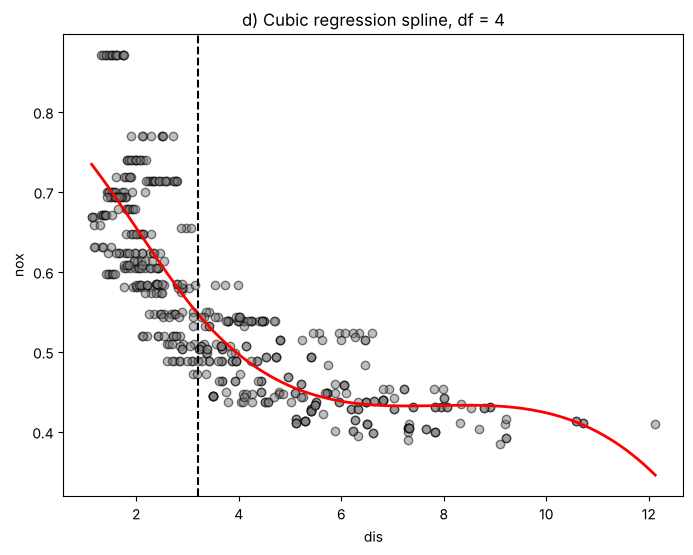

In [8]:
design = MS([bs('dis', df=4, name='bs(dis)')], intercept=True)
X = design.fit_transform(Boston)
M_bs = sm.OLS(y, X).fit()
print(summarize(M_bs))
print('knot (median of dis):', np.round(np.quantile(Boston['dis'], [0.5]), 4))
print('RSS:', round(np.sum(M_bs.resid**2), 4))

fig, ax = subplots(figsize=(8, 6))
ax.scatter(Boston['dis'], y, facecolor='gray', edgecolor='k', alpha=0.5)
ax.plot(dis_grid, M_bs.predict(design.transform(df_new)), 'r', linewidth=2)
ax.axvline(np.median(Boston['dis']), linestyle='--', color='k')
ax.set_xlabel('dis'); ax.set_ylabel('nox')
ax.set_title('d) Cubic regression spline, df = 4');

With df = 4, bs() builds a cubic spline with 3 degrees of freedom from the cubic basis plus 1 interior knot (the intercept is added separately). I did not choose the knot by hand: bs() places knots at uniform quantiles of dis, so the single knot sits at the median, dis = 3.207 (dashed line). This puts knots where the data are dense. All basis coefficients are significant and the RSS is 1.923, slightly better than the cubic polynomial. The fit looks very close to the cubic in a), but it behaves better at the right boundary.

e) Regression splines for a range of degrees of freedom.

,df,RSS
0,3,1.9341
1,4,1.9228
2,5,1.8402
3,6,1.8340
4,7,1.8299
5,8,1.8170
6,9,1.8257
7,10,1.7925
8,11,1.7970
9,12,1.7890


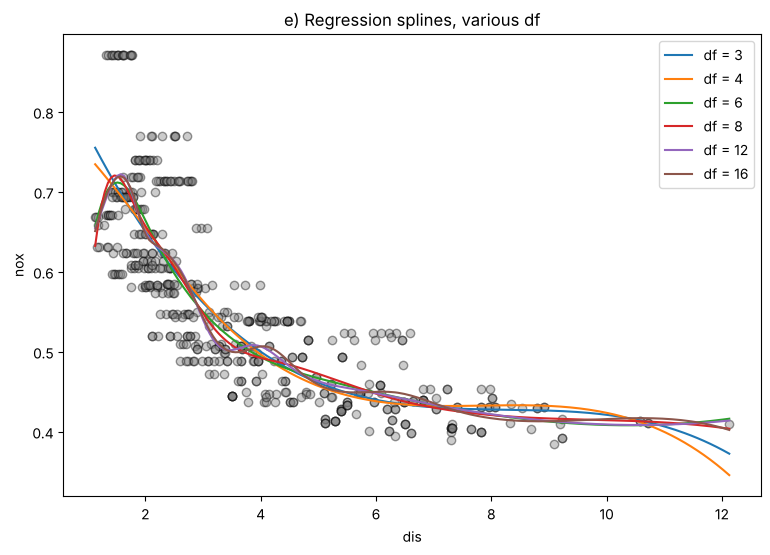

In [9]:
df_range = range(3, 17)
fig, ax = subplots(figsize=(9, 6))
ax.scatter(Boston['dis'], y, facecolor='gray', edgecolor='k', alpha=0.4)
rss_bs = []
for k in df_range:
    design = MS([bs('dis', df=k)], intercept=True)
    M = sm.OLS(y, design.fit_transform(Boston)).fit()
    rss_bs.append(np.sum(M.resid**2))
    if k in (3, 4, 6, 8, 12, 16):
        ax.plot(dis_grid, M.predict(design.transform(df_new)), linewidth=1.5,
                label=f'df = {k}')
ax.set_xlabel('dis'); ax.set_ylabel('nox')
ax.set_title('e) Regression splines, various df')
ax.legend()
pd.DataFrame({'df': df_range, 'RSS': np.round(rss_bs, 4)})

df = 3 means no interior knots, so it reproduces the cubic polynomial (RSS 1.934). The RSS falls overall as df grows, down to about 1.78, but not monotonically: changing df moves all the quantile knots, so the models are not nested. Larger df gives wigglier fits, especially for dis < 4 where the data are clustered, but the splines stay much more stable at the right boundary than the high-degree polynomials in b).

f) Choosing the degrees of freedom by 10-fold cross-validation.

best df: 10


,df,CV MSE
0,3,0.003854
1,4,0.003864
2,5,0.003701
3,6,0.003696
4,7,0.003696
5,8,0.003689
6,9,0.003718
7,10,0.003672
8,11,0.003681
9,12,0.003672


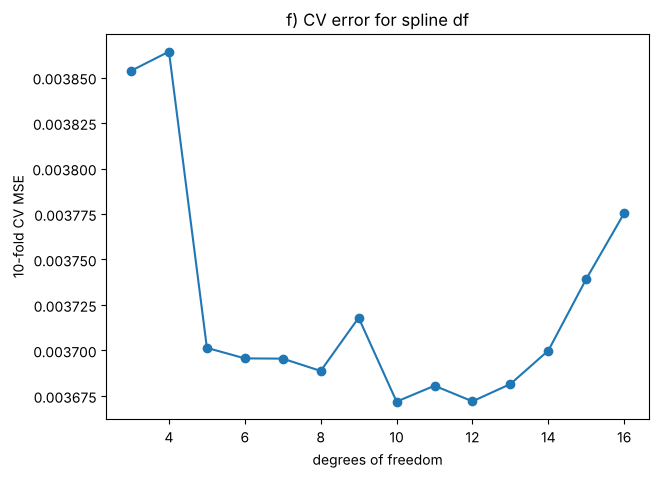

In [10]:
cv_bs = []
for k in df_range:
    M = sklearn_sm(sm.OLS, MS([bs('dis', df=k)], intercept=True))
    res = cross_validate(M, Boston[['dis']], y, cv=cv)
    cv_bs.append(np.mean(res['test_score']))
print('best df:', list(df_range)[int(np.argmin(cv_bs))])

fig, ax = subplots(figsize=(7, 5))
ax.plot(list(df_range), cv_bs, 'o-')
ax.set_xlabel('degrees of freedom'); ax.set_ylabel('10-fold CV MSE')
ax.set_title('f) CV error for spline df')
pd.DataFrame({'df': df_range, 'CV MSE': np.round(cv_bs, 6)})

The minimum CV error is at df = 10 (MSE about 0.00367), with df = 12 tied. The curve is very flat from df = 5 to 13, though: every value is within about 1% of the minimum. By the one-standard-error idea, a simpler spline with df around 5 or 6 is just as defensible and less wiggly. Unlike the polynomials, the CV error does not explode as flexibility grows, because the local spline basis keeps the variance under control. Every spline from df = 5 on beats the best polynomial (0.00385).

## Exercise 11

Note on the text: the lettering in the exercise is shifted. The loop in f) repeats steps d) and e), and the plot referred to in g) is the one made in f).

a) Generate Y, X1 and X2 with n = 100. The predictors are made correlated on purpose: with independent predictors backfitting converges in essentially one step and the exercise shows nothing.

In [11]:
rng = np.random.default_rng(0)
n = 100
X1 = rng.normal(size=n)
X2 = 0.8 * X1 + rng.normal(scale=0.6, size=n)
Y = 2 + 3 * X1 - 1.5 * X2 + rng.normal(size=n)
print('corr(X1, X2):', round(np.corrcoef(X1, X2)[0, 1], 3))

corr(X1, X2): 0.814


b) The function simple_reg() fits a simple linear regression and returns the intercept and slope.

In [12]:
def simple_reg(outcome, feature):
    X = sm.add_constant(feature)
    results = sm.OLS(outcome, X).fit()
    return results.params[0], results.params[1]

c) Initialize beta1 at a value far from the truth.

In [13]:
beta1 = 10.0

d) and e) Keeping beta1 fixed, regress Y − beta1·X1 on X2 to get beta0 and beta2. Then, keeping beta2 fixed, regress Y − beta2·X2 on X1 to get beta0 and beta1.

f) Repeat d) and e) 1,000 times, storing the estimates at each iteration.

In [14]:
n_iter = 1000
beta0_hist = np.zeros(n_iter)
beta1_hist = np.zeros(n_iter)
beta2_hist = np.zeros(n_iter)
for i in range(n_iter):
    beta0, beta2 = simple_reg(Y - beta1 * X1, X2)
    beta0, beta1 = simple_reg(Y - beta2 * X2, X1)
    beta0_hist[i], beta1_hist[i], beta2_hist[i] = beta0, beta1, beta2

history = pd.DataFrame({'iteration': np.arange(1, n_iter + 1),
                        'beta0': beta0_hist,
                        'beta1': beta1_hist,
                        'beta2': beta2_hist})
history.iloc[list(range(10)) + [n_iter - 1]].round(6)

,iteration,beta0,beta1,beta2
0,1,1.679838,7.612401,-7.055661
1,2,1.742506,6.031492,-5.157925
2,3,1.784000,4.984720,-3.901371
3,4,1.811475,4.291617,-3.069365
4,5,1.829667,3.832691,-2.518466
5,6,1.841713,3.528821,-2.153698
6,7,1.849689,3.327619,-1.912172
7,8,1.854970,3.194396,-1.752251
8,9,1.858466,3.106184,-1.646361
9,10,1.860782,3.047777,-1.576248


g) Multiple linear regression of Y on X1 and X2, overlaid with axline() on the backfitting plot.

             coef  std err       t  P>|t|
intercept  1.8653    0.114  16.392    0.0
X1         2.9333    0.202  14.491    0.0
X2        -1.4388    0.198  -7.277    0.0


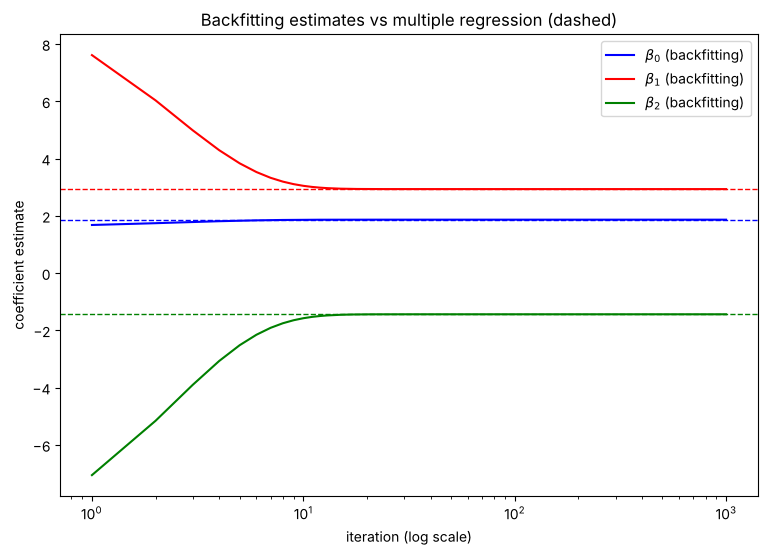

In [15]:
df11 = pd.DataFrame({'X1': X1, 'X2': X2, 'Y': Y})
design = MS(['X1', 'X2'], intercept=True)
M = sm.OLS(df11['Y'], design.fit_transform(df11)).fit()
print(summarize(M))
b_mlr = M.params.values

fig, ax = subplots(figsize=(9, 6))
ax.plot(history['iteration'], history['beta0'], 'b', label=r'$\beta_0$ (backfitting)')
ax.plot(history['iteration'], history['beta1'], 'r', label=r'$\beta_1$ (backfitting)')
ax.plot(history['iteration'], history['beta2'], 'g', label=r'$\beta_2$ (backfitting)')
for b, c in zip(b_mlr, ['b', 'r', 'g']):
    ax.axline((0, b), slope=0, color=c, linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_xlabel('iteration (log scale)')
ax.set_ylabel('coefficient estimate')
ax.set_title('Backfitting estimates vs multiple regression (dashed)')
ax.legend();

The backfitting estimates converge exactly to the multiple regression coefficients (1.8653, 2.9333, −1.4388), shown as dashed lines. This is expected: backfitting is coordinate-wise minimization of the RSS, which is convex, so it converges to the least squares solution.

h) Number of iterations needed for a good approximation.

In [16]:
err = np.max(np.abs(history[['beta0', 'beta1', 'beta2']].values - b_mlr), axis=1)
for tol in [1e-2, 1e-3, 1e-6]:
    print(f'first iteration with max abs error < {tol:g}:', int(np.argmax(err < tol)) + 1)

first iteration with max abs error < 0.01: 17
first iteration with max abs error < 0.001: 22
first iteration with max abs error < 1e-06: 39


Very few iterations are needed. The largest absolute difference from the multiple regression estimates drops below 0.01 at iteration 17, below 0.001 at iteration 22 and below 10⁻⁶ at iteration 39; the remaining iterations change nothing. The error shrinks by a roughly constant factor each iteration, about corr(X1, X2)² ≈ 0.66, so convergence is slower the more correlated the predictors are. With independent predictors a single iteration would be enough.